# <Center> INF - Deliverable 1

<center> Group: Magnus Bigum and Georg Hagen
<center> Date: 16.10.2026

# Task 1: Temperature

In [ ]:
import pandas as pd

import requests

import matplotlib.pyplot as plt 

client_id = open('frost_client_id.txt').read().strip()


# Define endpoint and parameters
endpoint = 'https://frost.met.no/observations/v0.jsonld'
parameters = {
'sources': 'SN17850',
'elements': 'mean(air_temperature P1D)',
'referencetime': '2025-01-01/2025-12-31',
}

# Issue an HTTP GET request
r = requests.get(endpoint, parameters, auth=(client_id,''))
# Extract JSON data
json = r.json()

# Check if the request worked, print out any errors
if r.status_code == 200:
    data = json['data']
    print('Data retrieved from frost.met.no!')
else:
    print('Error! Returned status code %s' % r.status_code)
    print('Message: %s' % json['error']['message'])
    print('Reason: %s' % json['error']['reason'])

rows=[]

for i in range(len(data)):
    row = pd.DataFrame(data[i]['observations'])
    row['referenceTime'] = data[i]['referenceTime']
    row['sourceId'] = data[i]['sourceId']
    rows.append(row)

df = pd.concat(rows, ignore_index=True)




In [18]:

def temperature_summary(df):
    summary = pd.DataFrame({
        "Statistics": ["Mean", "Median", "min", "max"],
        "Temperature (°C)": [
            df["value"].mean(),
            df["value"].median(),
            df["value"].min(),
            df["value"].max()
        ]
    })

    print("Temperature Summary - 2025")
    print(summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.2f}"
    ))

temperature_summary(df)



Temperature Summary - 2025
Statistics  Temperature (°C)
      Mean              7.90
    Median              8.35
       min            -16.10
       max             24.50


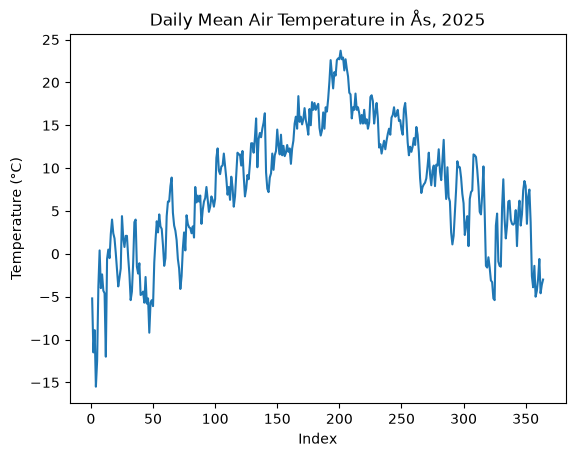

In [24]:
df_pt0h = df[df["timeOffset"] == "PT0H"].copy()
df_pt0h.index = range(1, len(df_pt0h) + 1)

df_pt0h.plot(
    y="value",
    kind="line",
    title="Daily Mean Air Temperature in Ås, 2025",
    xlabel="Index",
    ylabel="Temperature (°C)",
    legend=False
)
plt.show()

# Task 2: Precipitation

# Task 3: Historical temperature data

In [26]:
# Define endpoint and parameters
parameters_1925 = {
'sources': 'SN17850',
'elements': 'mean(air_temperature P1D)',
'referencetime': '1925-01-01/1925-12-31',
}

r_1925 = requests.get(
    endpoint, params=parameters_1925, auth=(client_id, "")
)

r_1925.raise_for_status()
data_1925 = r_1925.json()["data"]

rows_1925 = []

for day in data_1925:
    row = pd.DataFrame(day["observations"])
    row["referenceTime"] = day["referenceTime"]
    rows_1925.append(row)

if rows_1925:
    df_1925 = pd.concat(rows_1925, ignore_index=True)
else:
    print("No observations found for 1925")

def temperature_summary_1925(df):
    summary = pd.DataFrame({
        "Statistics": ["Mean", "Median", "min", "max"],
        "Temperature (°C)": [
            df["value"].mean(),
            df["value"].median(),
            df["value"].min(),
            df["value"].max()
        ]
    })

    print("Temperature Summary - 1925")
    print(summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.2f}"
    ))


temperature_summary_1925(df_1925)
print("")
temperature_summary(df)

Temperature Summary - 1925
Statistics  Temperature (°C)
      Mean              5.31
    Median              5.30
       min            -20.70
       max             24.30

Temperature Summary - 2025
Statistics  Temperature (°C)
      Mean              7.90
    Median              8.35
       min            -16.10
       max             24.50
